In [6]:
# Install AutoGluon
# Fast install: https://github.com/autogluon/autogluon/issues/3993

!pip install uv
!uv pip install --system autogluon --no-cache

Using Python 3.12.7 environment at: /Users/alexandergudmundsson/anaconda3
Audited 1 package in 157ms


In [7]:
# Import necessary libraries
import pandas as pd
import numpy as np
from datetime import datetime

# Import AutoGluon TimeSeries libraries
from autogluon.timeseries import TimeSeriesDataFrame, TimeSeriesPredictor

# Import libraries for evaluation metrics and plotting
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt

In [8]:
# Load data file "Exports-by-branches-of-processing-and-countries-2015-2025.parquet"
# This dataset contains export data by branches of processing and countries over time.
df = pd.read_parquet('data/Exports-by-branches-of-processing-and-countries-2015-2025.parquet')


In [9]:
# Pivot the data to a wide format for time series analysis.
# This reshapes the data so that 'Month', 'Country', and 'Branches' form the index,
# and 'Unit' values become columns, with 'DATA' as the values.
df_wide = (
    pd.pivot_table(
        df,
        index=["Month", "Country", "Branches"],
        columns="Unit",
        values="DATA",
        aggfunc="sum",
        dropna=False,
    )
    .reset_index()
)
df_wide.head()

Unit,Month,Country,Branches,Fob value,Quantity,Tonnes
0,2015M01,Afghanistan,"00 Whole fish, fresh, chilled or on ice",0,0,0
1,2015M01,Afghanistan,"01 Fish fillets, fresh, chilled or on ice",0,0,0
2,2015M01,Afghanistan,"02 Other marine products, fresh or chilled",0,0,0
3,2015M01,Afghanistan,"10 Sea frozen fish, whole",0,0,0
4,2015M01,Afghanistan,"11 Sea frozen fish fillets, in blocks",0,0,0


In [10]:
# Data Wrangling for Time Series Analysis

# Use "Fob value" as the target variable for forecasting.
# Drop the 'Quantity' and 'Tonnes' columns as they are not needed for this task.
df_wide = df_wide[["Month", "Country", "Branches", "Fob value"]]
df_wide = df_wide.rename(columns={"Fob value": "target"})

# Parse the 'Month' column into a datetime format, representing the start of the month.
df_wide["timestamp"] = pd.to_datetime(df_wide["Month"].astype(str).str.replace("M", "-"), format="%Y-%m")
df_wide = df_wide.drop(columns="Month")

# Ensure the target variable is of a numeric type, coercing errors to NaN.
df_wide["target"] = pd.to_numeric(df_wide["target"], errors="coerce")

# Create a unique series ID by combining 'Country' and 'Branches'.
# This is required by AutoGluon to identify individual time series.
df_wide["series_id"] = df_wide["Country"].astype(str) + " • " + df_wide["Branches"].astype(str)

# Sort the data by 'series_id' and 'timestamp' to ensure the correct order for time series.
df_wide = df_wide.sort_values(["series_id", "timestamp"]).reset_index(drop=True)

# Drop time series where the target variable is always zero across the entire history.
# These series do not contain any signal for forecasting.
series_has_signal = df_wide.groupby("series_id")["target"].transform(lambda s: (s != 0).any())
df_wide = df_wide[series_has_signal].copy()

# Keep a separate DataFrame with metadata for later grouping and analysis.
series_meta = df_wide[["series_id", "Country", "Branches"]].drop_duplicates()

print("Rows after cleaning:", len(df_wide))
print("Unique series:", series_meta.shape[0])

Rows after cleaning: 352679
Unique series: 2777


In [11]:
df_wide.head()

Unit,Country,Branches,target,timestamp,series_id
10033,Albania,49 Agricultural products n.e.s.,0.0,2015-01-01,Albania • 49 Agricultural products n.e.s.
10034,Albania,49 Agricultural products n.e.s.,0.0,2015-02-01,Albania • 49 Agricultural products n.e.s.
10035,Albania,49 Agricultural products n.e.s.,0.0,2015-03-01,Albania • 49 Agricultural products n.e.s.
10036,Albania,49 Agricultural products n.e.s.,0.0,2015-04-01,Albania • 49 Agricultural products n.e.s.
10037,Albania,49 Agricultural products n.e.s.,0.0,2015-05-01,Albania • 49 Agricultural products n.e.s.


In [12]:
# Define prediction length (number of months to forecast)
prediction_length = 12  # last 12 months as test

# Identify unique months and the test set months
uniq_months = np.sort(df_wide["timestamp"].unique())
test_months = set(uniq_months[-prediction_length:])

# Split the data into training and testing sets based on the identified months
train_df = df_wide[~df_wide["timestamp"].isin(test_months)].copy()
test_df  = df_wide[df_wide["timestamp"].isin(test_months)].copy()

# Define the columns needed for the TimeSeriesDataFrame
cols = ["series_id", "timestamp", "target"]

# Create TimeSeriesDataFrame for training
ts_train = TimeSeriesDataFrame.from_data_frame(
    train_df[cols],
    id_column="series_id",
    timestamp_column="timestamp",
)

# Create TimeSeriesDataFrame for testing
ts_test = TimeSeriesDataFrame.from_data_frame(
    test_df[cols],
    id_column="series_id",
    timestamp_column="timestamp",
)

In [13]:
# Initialize the TimeSeriesPredictor with the specified prediction length, target variable, frequency, and evaluation metric.
predictor = TimeSeriesPredictor(
    prediction_length=prediction_length,
    target="target",
    freq="MS", # 'MS' indicates Month Start frequency
    eval_metric="WAPE", # Weighted Absolute Percentage Error
)

# Fit the predictor to the training data.
# presets="medium_quality" trains a diverse set of models for good performance.
# time_limit sets the maximum training time in seconds.
# random_seed ensures reproducibility of the training process.
predictor.fit(
    ts_train,
    presets="best_quality",
    #time_limit=600,
    random_seed=42,
)

Beginning AutoGluon training...
AutoGluon will save models to '/Users/alexandergudmundsson/Documents/Gagnathon2025GagnaGollarar/AutogluonModels/ag-20251108_184539'
=================== System Info ===================
AutoGluon Version:  1.4.0
Python Version:     3.12.7
Operating System:   Darwin
Platform Machine:   arm64
Platform Version:   Darwin Kernel Version 25.1.0: Mon Oct 20 19:34:03 PDT 2025; root:xnu-12377.41.6~2/RELEASE_ARM64_T8112
CPU Count:          8
GPU Count:          1
Memory Avail:       4.03 GB / 16.00 GB (25.2%)
Disk Space Avail:   17.58 GB / 228.27 GB (7.7%)
Setting presets to: best_quality

Fitting with arguments:
{'enable_ensemble': True,
 'eval_metric': WAPE,
 'freq': 'MS',
 'hyperparameters': 'default',
 'known_covariates_names': [],
 'num_val_windows': 2,
 'prediction_length': 12,
 'quantile_levels': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
 'random_seed': 42,
 'refit_every_n_windows': 1,
 'refit_full': False,
 'skip_model_selection': False,
 'target': 'tar

In [14]:
# Shows all models tried, sorted by validation score
leaderboard = predictor.leaderboard(silent=False)

                           model  score_val  pred_time_val  fit_time_marginal  fit_order
0               WeightedEnsemble  -0.437896      23.331109           4.816015         13
1   ChronosFineTuned[bolt_small]  -0.454775       3.441760         535.424989          8
2     ChronosZeroShot[bolt_base]  -0.471008      11.889642          16.561960          7
3                           TiDE  -0.486515       1.566226         560.025755         12
4          DynamicOptimizedTheta  -0.495258       2.328043           4.787577          5
5      TemporalFusionTransformer  -0.498109       0.749952         246.125226          9
6                        AutoETS  -0.505214       7.400296           6.559748          6
7               RecursiveTabular  -0.540782       0.340194           7.091708          2
8                         DeepAR  -0.541126      10.968298         183.064573         10
9                  DirectTabular  -0.541983       0.523612           5.134402          3
10                 Se

In [15]:
# Get information about the trained predictor and the best model.
info = predictor.info()

# Extract the name of the best model and its validation score.
best_model = info["best_model"]
best_score = -info["best_model_score_val"]  # Flip the sign as WAPE is a minimization metric, but AutoGluon stores it as maximization

# Print the best model and its validation score.
print("Best model:", best_model)
print("Best validation WAPE:", best_score)

# Get detailed information about all trained models.
mi = info["model_info"]

# If the best model is a WeightedEnsemble, print details about its base models and their weights.
if best_model == "WeightedEnsemble":
    we = mi["WeightedEnsemble"]
    print("\nEnsemble validation WAPE:", -we["val_score"]) # Flip the sign for WAPE
    print("Base models and weights:")
    for base_name, w in we["model_weights"].items():
        base_rmse = -mi[base_name]["val_score"] # Flip the sign for base model WAPE
        print(f"  - {base_name:22s}  weight={float(w):.4f}  val_RMSE={base_rmse:.3f}")
else:
    # If the best is not an ensemble, print details about the best model.
    bm = mi[best_model]
    print("\nBest model details:")
    print("  type:", bm["model_type"])
    print("  val_RMSE:", -bm["val_score"]) # Flip the sign for WAPE
    print("  fit_time:", bm["fit_time"], "s")
    print("  predict_time:", bm["predict_time"], "s")

Best model: WeightedEnsemble
Best validation WAPE: 0.4378960962293182

Ensemble validation WAPE: 0.4378960962293182
Base models and weights:
  - RecursiveTabular        weight=0.0600  val_RMSE=0.541
  - NPTS                    weight=0.0500  val_RMSE=0.618
  - DynamicOptimizedTheta   weight=0.1700  val_RMSE=0.495
  - ChronosZeroShot[bolt_base]  weight=0.0200  val_RMSE=0.471
  - ChronosFineTuned[bolt_small]  weight=0.5500  val_RMSE=0.455
  - PatchTST                weight=0.0500  val_RMSE=0.884
  - TiDE                    weight=0.1000  val_RMSE=0.487


In [16]:
# Use the predictor to generate forecasts for the next 'prediction_length' time steps
forecast = predictor.predict(ts_train)

# Work with it directly as a DataFrame
pred = forecast.reset_index()
# Rename 'item_id' to 'series_is' if it exists, for consistency
if "item_id" in pred.columns and "series_id" not in pred.columns:
    pred = pred.rename(columns={"item_id": "series_id"})

# Prepare the truth values from the test set
truth = ts_test.reset_index()
# Rename 'item_id' to 'series_is' if it exists, for consistency
if "item_id" in truth.columns and "series_id" not in truth.columns:
    truth = truth.rename(columns={"item_id": "series_id"})

# Determine the column name for the predicted values (either 'mean' or '0.5' quantile)
yhat_col = "mean" if "mean" in pred.columns else ("0.5" if "0.5" in pred.columns else
               [c for c in pred.columns if c not in {"series_id", "timestamp"}][0])

# Align and merge the predictions, true values, and metadata
# This combines the forecast and actual values for each timer series at each timestamp,
# and includes the original Country and Branches information.
pred = pred[["series_id", "timestamp", yhat_col]].copy()
truth = truth[["series_id", "timestamp", "target"]].copy()

aligned = (
    pred.merge(truth, on=["series_id", "timestamp"], how="inner")
        .merge(series_meta, on="series_id", how="left")
        # Rename the predicted and true value columns for clarity
        .rename(columns={yhat_col: "y_pred", "target": "y_true"})
        # Sort the results for easier analysis
        .sort_values(["series_id", "timestamp"])
        .reset_index(drop=True)
)

# Ensure the true and predicted target variables are of float type
aligned["y_true"] = aligned["y_true"].apply(lambda x: float(x[0]) if isinstance(x, (np.ndarray, list)) else float(x))
aligned["y_pred"] = aligned["y_pred"].apply(lambda x: float(x[0]) if isinstance(x, (np.ndarray, list)) else float(x))
print("Aligned rows:", f"{len(aligned):,}")

Model not specified in predict, will default to the model with the best validation score: WeightedEnsemble


Aligned rows: 33,324


In [17]:
# Compute overall model metrics
y_true = aligned["y_true"].astype(float).values
y_pred = aligned["y_pred"].astype(float).values

# Basic metrics
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mae = mean_absolute_error(y_true, y_pred)

# Weighted Absolute Percentage Error (WAPE)
# This is a common metric for time series forecasting that is less sensitive to outliers than RMSE.
den = np.sum(np.abs(y_true))
wape = np.nan if den == 0 else np.sum(np.abs(y_true - y_pred)) / den
accuracy = 1 - wape if not np.isnan(wape) else np.nan

# Coefficient of Determination (R²)
# This metric indicates how well the predicted values explain the variance in the true values.
r2 = r2_score(y_true, y_pred)

# --- Print results ---
print(f"RMSE: {rmse:.2f}")
print(f"MAE:  {mae:.2f}")
print(f"WAPE: {wape:.2%}")
print(f"Accuracy: {accuracy:.2%}")
print(f"R²: {r2:.3f}")

RMSE: 107.93
MAE:  11.49
WAPE: 39.43%
Accuracy: 60.57%
R²: 0.940


Overall WAPE: 39.43%
Overall R²:   0.940

Top 10 branches (by WAPE):


,Branches,WAPE,R2,Accuracy
0,"01 Fish fillets, fresh, chilled or on ice",0.159193,0.965465,0.840807
1,28 Dried fish heads,0.205878,0.936308,0.794122
2,71 Products of power intensive plants,0.219540,0.955235,0.780460
3,"00 Whole fish, fresh, chilled or on ice",0.359029,0.854947,0.640971
4,21 Uncured salted fish,0.360981,0.875188,0.639019
5,"89 Other manufacturing, n.e.s.",0.370569,0.878406,0.629431
6,16 Frozen fish fillets n.e.s.,0.428816,0.793382,0.571184
7,41 Farmed fish,0.478372,0.691801,0.521628
8,"29 Other dried, salted fish",0.481650,0.786096,0.518350
9,"12 Sea frozen fish fillets, n.e.s.",0.482445,0.728560,0.517555


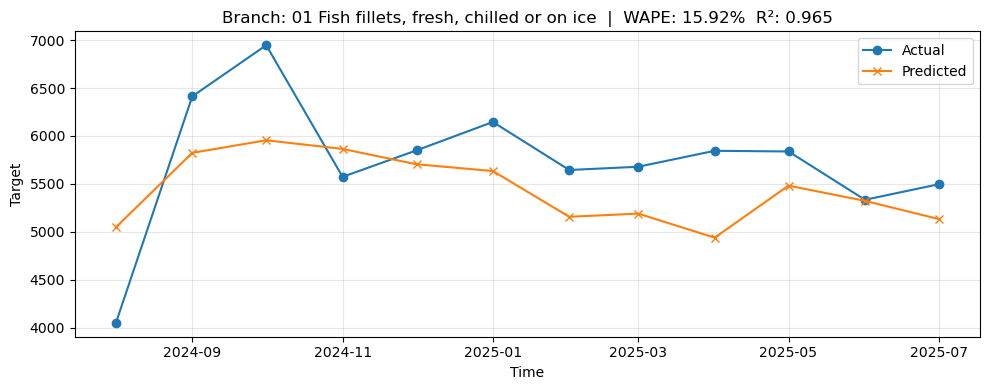

In [18]:
# Create a copy of the aligned DataFrame to work with
aligned = pd.DataFrame(aligned).copy()

# Define custom evaluation metrics functions
# Weighted Absolute Percentage Error (WAPE)
def wape(y_true, y_pred):
    y_true = np.asarray(y_true, float)
    y_pred = np.asarray(y_pred, float)
    denom = np.sum(np.abs(y_true))
    return np.nan if denom == 0 else np.sum(np.abs(y_true - y_pred)) / denom

# Safe R-squared calculation (handles cases with only one data point)
def r2_safe(y_true, y_pred):
    y_true = np.asarray(y_true, float)
    y_pred = np.asarray(y_pred, float)
    return r2_score(y_true, y_pred) if len(y_true) > 1 else np.nan

# Calculate and print overall metrics
overall_wape = wape(aligned["y_true"], aligned["y_pred"])
overall_r2   = r2_safe(aligned["y_true"], aligned["y_pred"])
print(f"Overall WAPE: {overall_wape:.2%}")
print(f"Overall R²:   {overall_r2:.3f}")

# Calculate and print metrics grouped by 'Branches'
# This helps in understanding the model's performance on different categories
by_branch = (
    aligned.groupby("Branches", dropna=False)
          .apply(lambda g: pd.Series({
               "WAPE": wape(g["y_true"], g["y_pred"]),
               "R2":   r2_safe(g["y_true"], g["y_pred"]),
          }),
          include_groups=False
    )
    .reset_index()
)
# Calculate Accuracy from WAPE
by_branch["Accuracy"] = 1 - by_branch["WAPE"]
# Sort by WAPE to see the best performing branches first
by_branch = by_branch.sort_values("WAPE").reset_index(drop=True)

print("\nTop 10 branches (by WAPE):")
# Display the top 10 branches with their calculated metrics
display(by_branch.head(10))

# Plot an example time series for the best performing branch
# Get the name of the best branch
best = by_branch.iloc[0]["Branches"]
# Filter the aligned data for the best branch
sub = aligned[aligned["Branches"] == best].copy()
# Sort the data by timestamp
sub = sub.sort_values("timestamp")
# Group by timestamp and sum the true and predicted values
sub = sub.groupby("timestamp")[["y_true", "y_pred"]].sum().reset_index()

# Create the plot
plt.figure(figsize=(10,4))
# Plot the actual values
plt.plot(sub["timestamp"], sub["y_true"], marker="o", label="Actual")
# Plot the predicted values
plt.plot(sub["timestamp"], sub["y_pred"], marker="x", label="Predicted")
# Set the title of the plot with the branch name and its WAPE and R² scores
plt.title(f"Branch: {best}  |  WAPE: {by_branch.loc[by_branch['Branches']==best,'WAPE'].values[0]:.2%}  "
          f"R²: {by_branch.loc[by_branch['Branches']==best,'R2'].values[0]:.3f}")
# Set labels for the axes
plt.xlabel("Time"); plt.ylabel("Target")
# Add a legend to the plot
plt.legend();
# Add a grid for better readability
plt.grid(alpha=0.3);
# Adjust layout to prevent labels overlapping
plt.tight_layout()
# Display the plot
plt.show()

In [24]:
print("Re-initializing and retraining the best model using the full dataset...")
ts_full = pd.concat([ts_train, ts_test])
# Re-initialize the TimeSeriesPredictor with the original settings
predictor = TimeSeriesPredictor(
    prediction_length=prediction_length, # This is 12 from your original script
    target="target",
    freq="MS", # 'MS' indicates Month Start frequency
    eval_metric="WAPE", # Weighted Absolute Percentage Error
)

# Fit the new predictor to the full dataset, using the same presets
# This will allow AutoGluon to find the best model, likely the WeightedEnsemble again
predictor.fit(
    ts_full,
    presets="medium_quality", # Use the same presets to allow AutoGluon to rebuild the WeightedEnsemble
    time_limit=600, # Use the same time limit as before
    random_seed=42, # Use the same random seed for reproducibility
)
print("Model retraining complete.")

No path specified. Models will be saved in: "AutogluonModels/ag-20251108_202315"
Beginning AutoGluon training... Time limit = 600s
AutoGluon will save models to '/Users/alexandergudmundsson/Documents/Gagnathon2025GagnaGollarar/AutogluonModels/ag-20251108_202315'
=================== System Info ===================
AutoGluon Version:  1.4.0
Python Version:     3.12.7
Operating System:   Darwin
Platform Machine:   arm64
Platform Version:   Darwin Kernel Version 25.1.0: Mon Oct 20 19:34:03 PDT 2025; root:xnu-12377.41.6~2/RELEASE_ARM64_T8112
CPU Count:          8
GPU Count:          1
Memory Avail:       4.15 GB / 16.00 GB (25.9%)
Disk Space Avail:   17.01 GB / 228.27 GB (7.5%)
Setting presets to: medium_quality

Fitting with arguments:
{'enable_ensemble': True,
 'eval_metric': WAPE,
 'freq': 'MS',
 'hyperparameters': 'light',
 'known_covariates_names': [],
 'num_val_windows': 1,
 'prediction_length': 12,
 'quantile_levels': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
 'random_seed': 42,

Re-initializing and retraining the best model using the full dataset...


Provided train_data has 352679 rows, 2777 time series. Median time series length is 127 (min=127, max=127). 

Provided data contains following columns:
	target: 'target'

AutoGluon will gauge predictive performance using evaluation metric: 'WAPE'
	This metric's sign has been flipped to adhere to being higher_is_better. The metric score can be multiplied by -1 to get the metric value.

Starting training. Start time is 2025-11-08 20:23:16
Models that will be trained: ['Naive', 'SeasonalNaive', 'RecursiveTabular', 'DirectTabular', 'ETS', 'Theta', 'Chronos[bolt_small]', 'TemporalFusionTransformer']
Training timeseries model Naive. Training for up to 66.6s of the 599.7s of remaining time.
	-0.5367       = Validation score (-WAPE)
	0.05    s     = Training runtime
	5.20    s     = Validation (prediction) runtime
Training timeseries model SeasonalNaive. Training for up to 74.3s of the 594.4s of remaining time.
	-0.5450       = Validation score (-WAPE)
	0.05    s     = Training runtime
	0.81  

Model retraining complete.


Generating 12-month future forecast...


Model not specified in predict, will default to the model with the best validation score: WeightedEnsemble


Generated 33324 future forecast data points.
Plotting forecast for: 01 Fish fillets, fresh, chilled or on ice


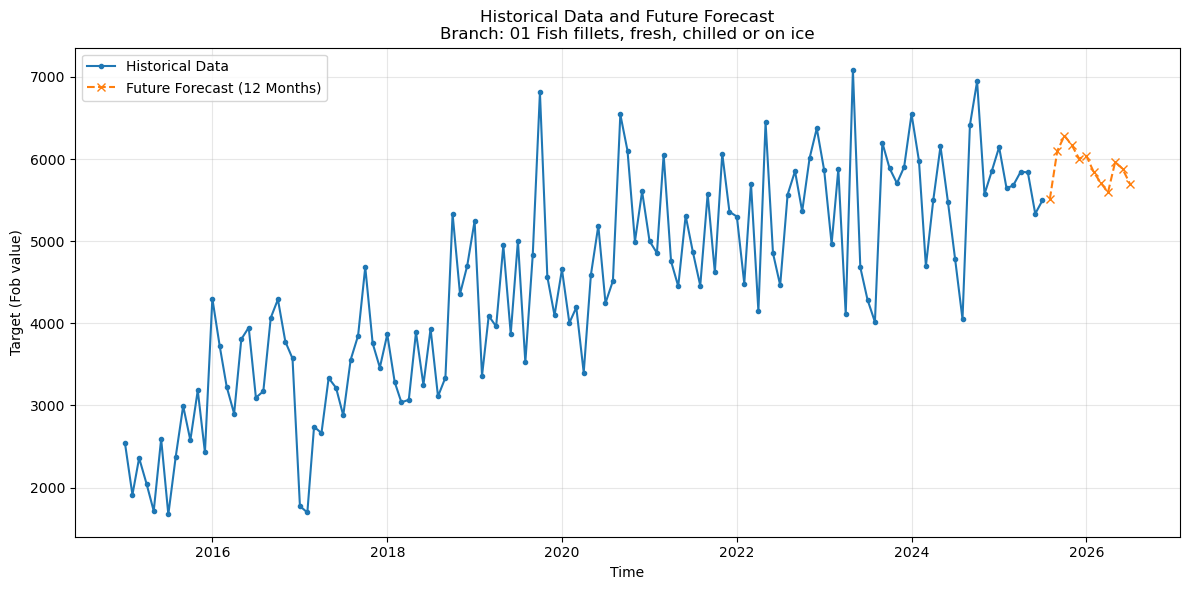

In [25]:
print("Generating 12-month future forecast...")

# Generate a future forecast.
# By passing ts_full, AutoGluon knows to forecast 12 steps *after* the end of this data.
future_forecast = predictor.predict(ts_full)

# Reset index to get 'timestamp' and 'item_id' (which we rename to 'series_id')
future_forecast_df = future_forecast.reset_index()

# Rename 'item_id' to 'series_id' for consistency, just as in your original script
if "item_id" in future_forecast_df.columns:
    future_forecast_df = future_forecast_df.rename(columns={"item_id": "series_id"})

print(f"Generated {len(future_forecast_df)} future forecast data points.")

# --- Prepare Data for Plotting ---

# 1. Define the branch you want to plot
target_branch_name = '01 Fish fillets, fresh, chilled or on ice'

# 2. Get the series_ids for that branch from your existing series_meta DataFrame
target_series_ids = series_meta[series_meta['Branches'] == target_branch_name]['series_id'].unique()

# 3. Get all historical data for that branch (from ts_full)
full_data_df = ts_full.reset_index()
if "item_id" in full_data_df.columns:
    full_data_df = full_data_df.rename(columns={"item_id": "series_id"})

branch_history_df = full_data_df[full_data_df['series_id'].isin(target_series_ids)]

# Aggregate history by timestamp (summing all 'Country' series for this branch)
agg_branch_history = branch_history_df.groupby('timestamp')[['target']].sum().reset_index()

# 4. Get the future forecast data for that branch
branch_forecast_df = future_forecast_df[future_forecast_df['series_id'].isin(target_series_ids)]

# Aggregate forecast by timestamp (using the 'mean' prediction)
agg_branch_forecast = branch_forecast_df.groupby('timestamp')[['mean']].sum().reset_index()

# --- Visualize the Results ---

print(f"Plotting forecast for: {target_branch_name}")

plt.figure(figsize=(12, 6))

# Plot the historical data
plt.plot(
    agg_branch_history['timestamp'],
    agg_branch_history['target'],
    label='Historical Data',
    marker='.'
)

# Plot the future forecast
plt.plot(
    agg_branch_forecast['timestamp'],
    agg_branch_forecast['mean'],
    label='Future Forecast (12 Months)',
    marker='x',
    linestyle='--'
)

# Add plot formatting
plt.title(f"Historical Data and Future Forecast\nBranch: {target_branch_name}")
plt.xlabel("Time")
plt.ylabel("Target (Fob value)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Preparing data for the combined plot...
Plotting full history and forecast for: 01 Fish fillets, fresh, chilled or on ice


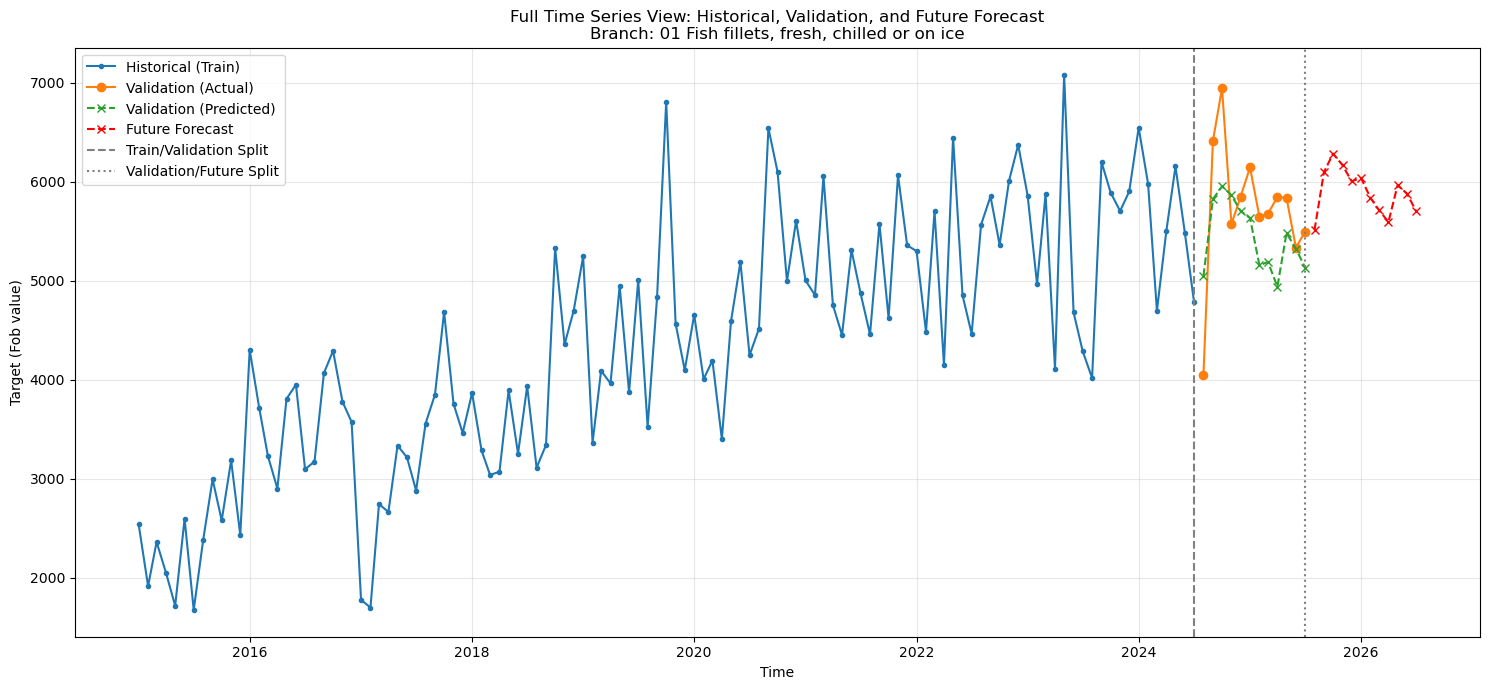

In [26]:
print("Preparing data for the combined plot...")

# --- 1. Define Target Branch and Series IDs ---
target_branch_name = '01 Fish fillets, fresh, chilled or on ice'
target_series_ids = series_meta[series_meta['Branches'] == target_branch_name]['series_id'].unique()

# --- 2. Aggregate Historical (Train) Data ---
# Use the original ts_train for this part
train_data_df = ts_train.reset_index()
if "item_id" in train_data_df.columns:
    train_data_df = train_data_df.rename(columns={"item_id": "series_id"})
    
branch_train_history = train_data_df[train_data_df['series_id'].isin(target_series_ids)]
agg_branch_train = branch_train_history.groupby('timestamp')[['target']].sum().reset_index()

# --- 3. Aggregate Validation (Test) Data ---
# Use the 'aligned' DataFrame, which has the original validation predictions
branch_validation_df = aligned[aligned['Branches'] == target_branch_name]
agg_branch_validation = branch_validation_df.groupby('timestamp')[['y_true', 'y_pred']].sum().reset_index()

# --- 4. Aggregate Future Forecast Data ---
# This uses 'future_forecast' from the retrained model in the previous step
future_forecast_df = future_forecast.reset_index()
if "item_id" in future_forecast_df.columns:
    future_forecast_df = future_forecast_df.rename(columns={"item_id": "series_id"})

branch_forecast_df = future_forecast_df[future_forecast_df['series_id'].isin(target_series_ids)]
agg_branch_forecast = branch_forecast_df.groupby('timestamp')[['mean']].sum().reset_index()

# --- 5. Visualize the Full Time Series ---

print(f"Plotting full history and forecast for: {target_branch_name}")

plt.figure(figsize=(15, 7))

# Plot Historical (Train) Data
plt.plot(
    agg_branch_train['timestamp'],
    agg_branch_train['target'],
    label='Historical (Train)',
    marker='.'
)

# Plot Validation (Actual) Data
plt.plot(
    agg_branch_validation['timestamp'],
    agg_branch_validation['y_true'],
    label='Validation (Actual)',
    marker='o'
)

# Plot Validation (Predicted) Data
plt.plot(
    agg_branch_validation['timestamp'],
    agg_branch_validation['y_pred'],
    label='Validation (Predicted)',
    marker='x',
    linestyle='--'
)

# Plot Future Forecast Data
plt.plot(
    agg_branch_forecast['timestamp'],
    agg_branch_forecast['mean'],
    label='Future Forecast',
    marker='x',
    linestyle='--',
    color='red'
)

# Add vertical lines to separate the periods
plt.axvline(agg_branch_train['timestamp'].max(), color='gray', linestyle='--', label='Train/Validation Split')
plt.axvline(agg_branch_validation['timestamp'].max(), color='gray', linestyle=':', label='Validation/Future Split')

# Add plot formatting
plt.title(f"Full Time Series View: Historical, Validation, and Future Forecast\nBranch: {target_branch_name}")
plt.xlabel("Time")
plt.ylabel("Target (Fob value)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Generating plots for the top 3 branches: ['01 Fish fillets, fresh, chilled or on ice', '28 Dried fish heads', '71 Products of power intensive plants', '00 Whole fish, fresh, chilled or on ice', '21 Uncured salted fish', '89 Other manufacturing, n.e.s.', '16 Frozen fish fillets n.e.s.', '41 Farmed fish', '29 Other dried, salted fish', '12 Sea frozen fish fillets, n.e.s.']

Plotting for: 01 Fish fillets, fresh, chilled or on ice


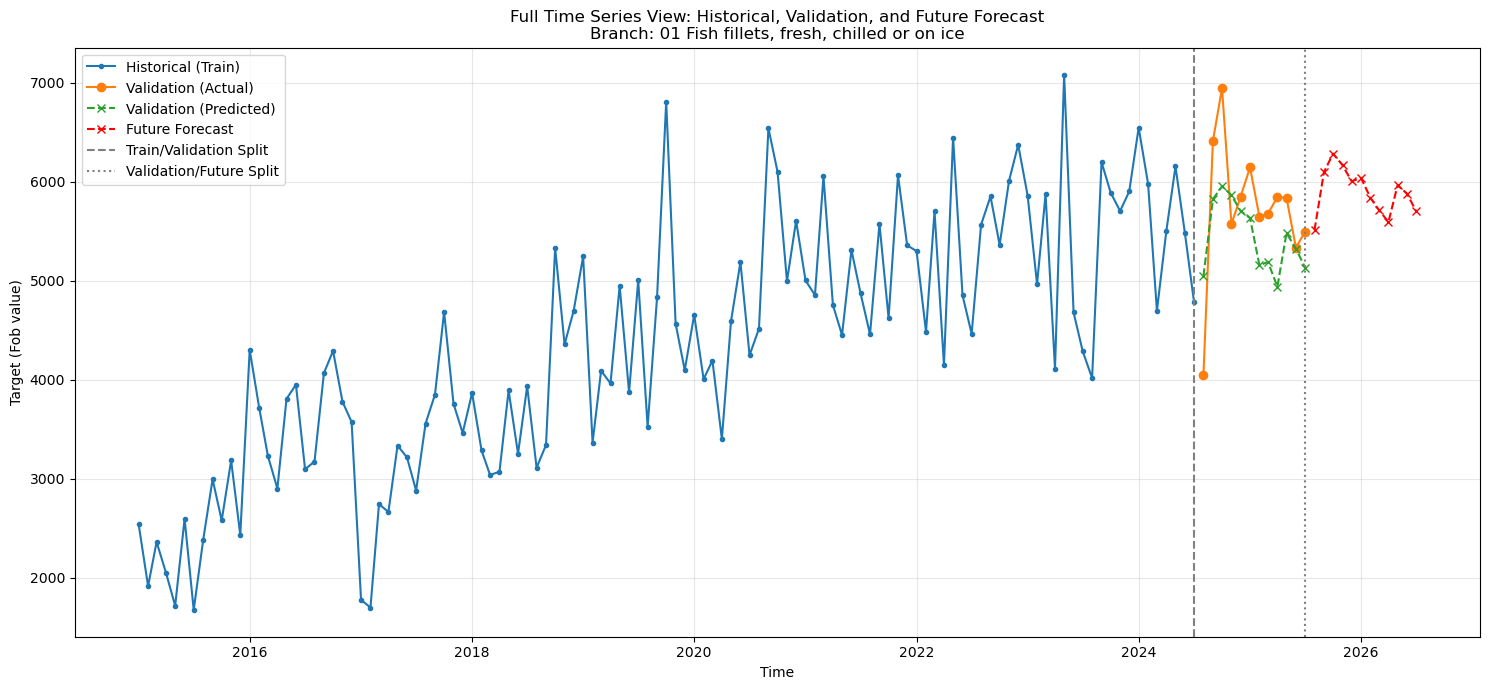


Plotting for: 28 Dried fish heads


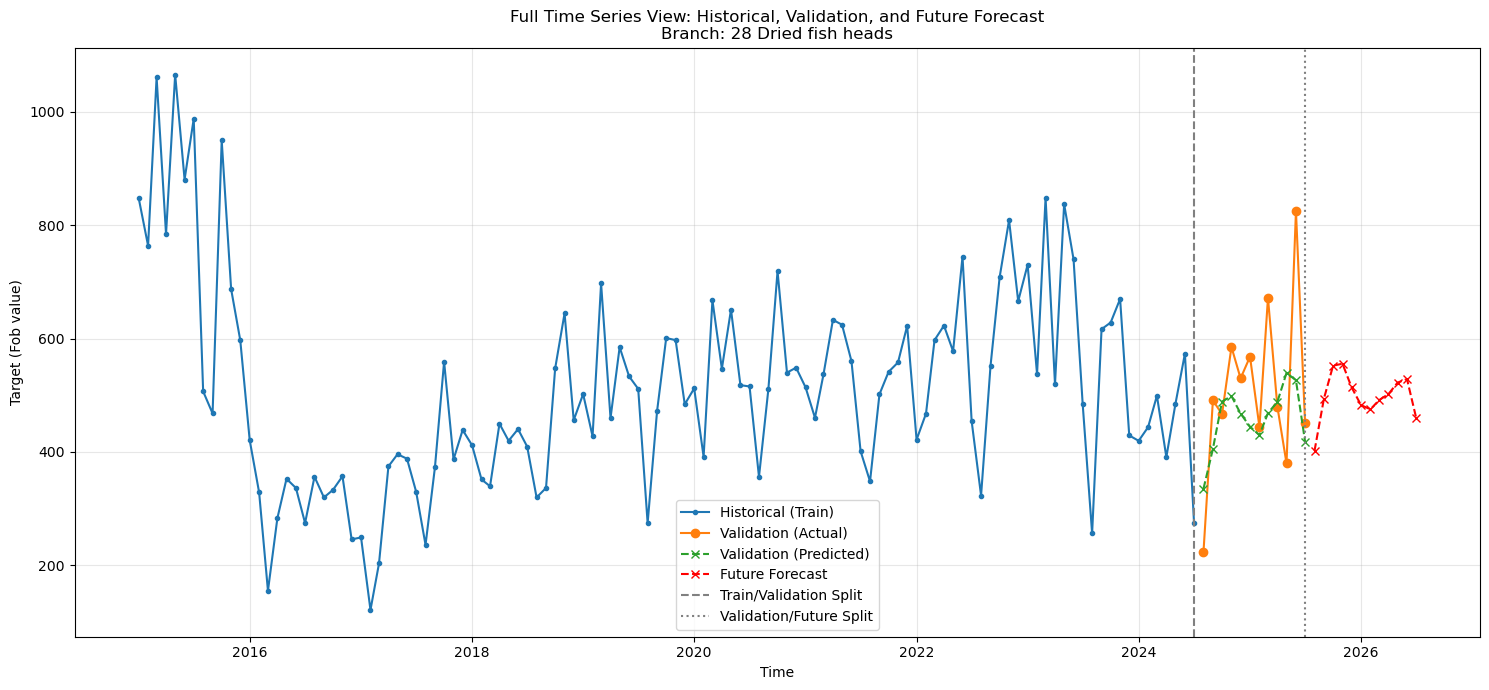


Plotting for: 71 Products of power intensive plants


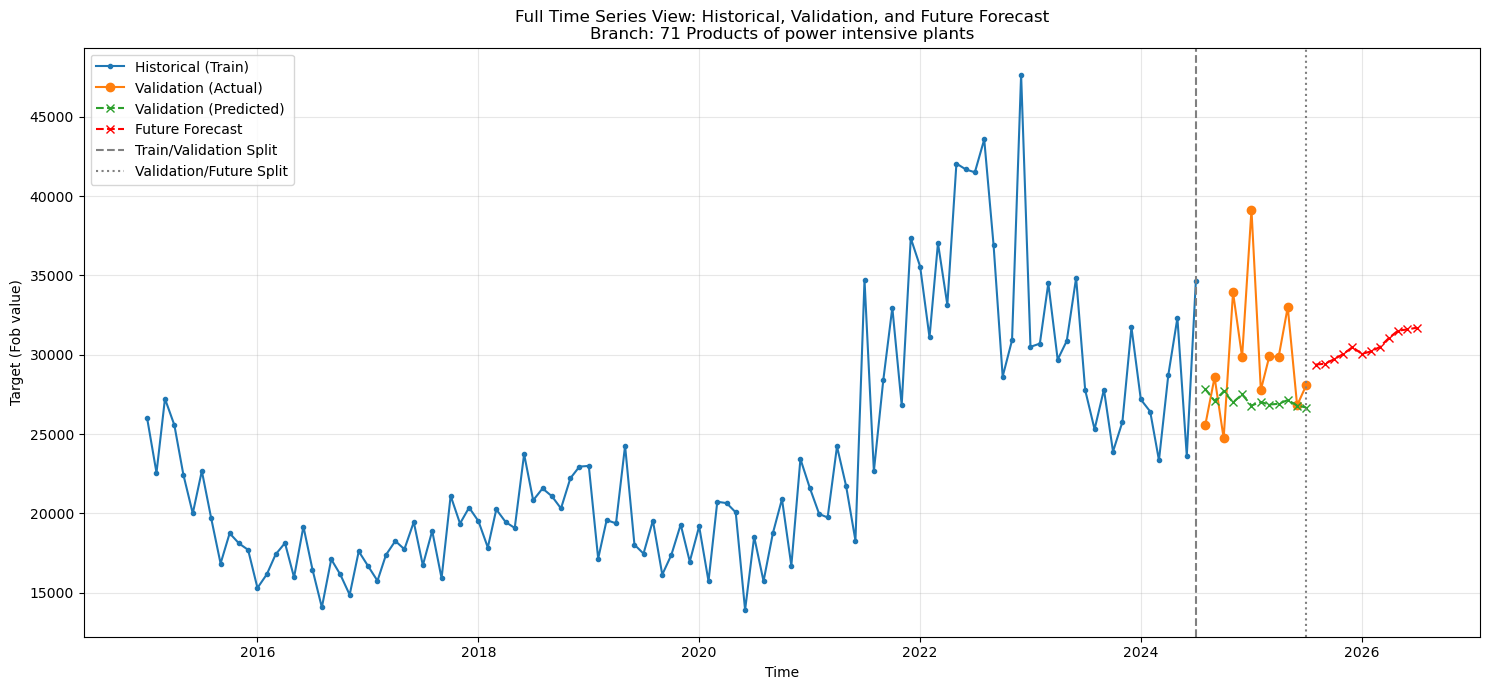


Plotting for: 00 Whole fish, fresh, chilled or on ice


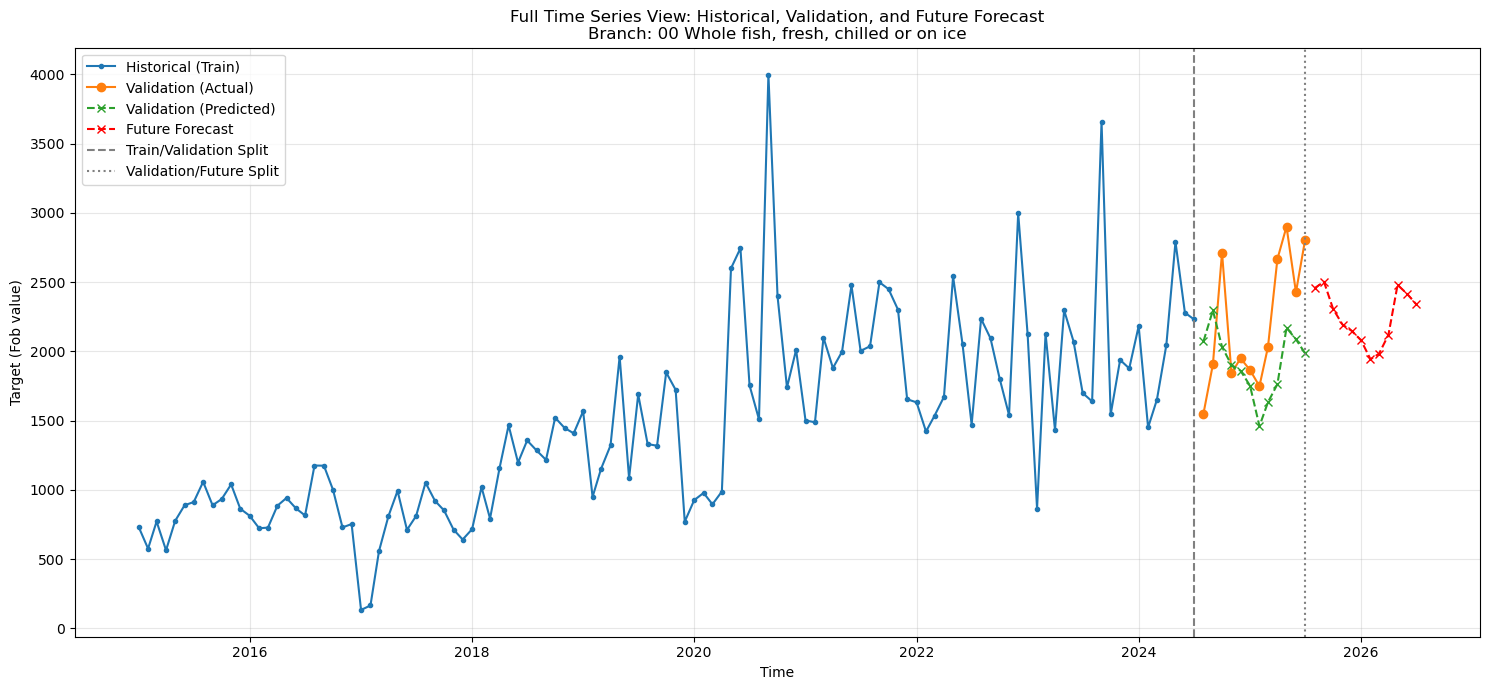


Plotting for: 21 Uncured salted fish


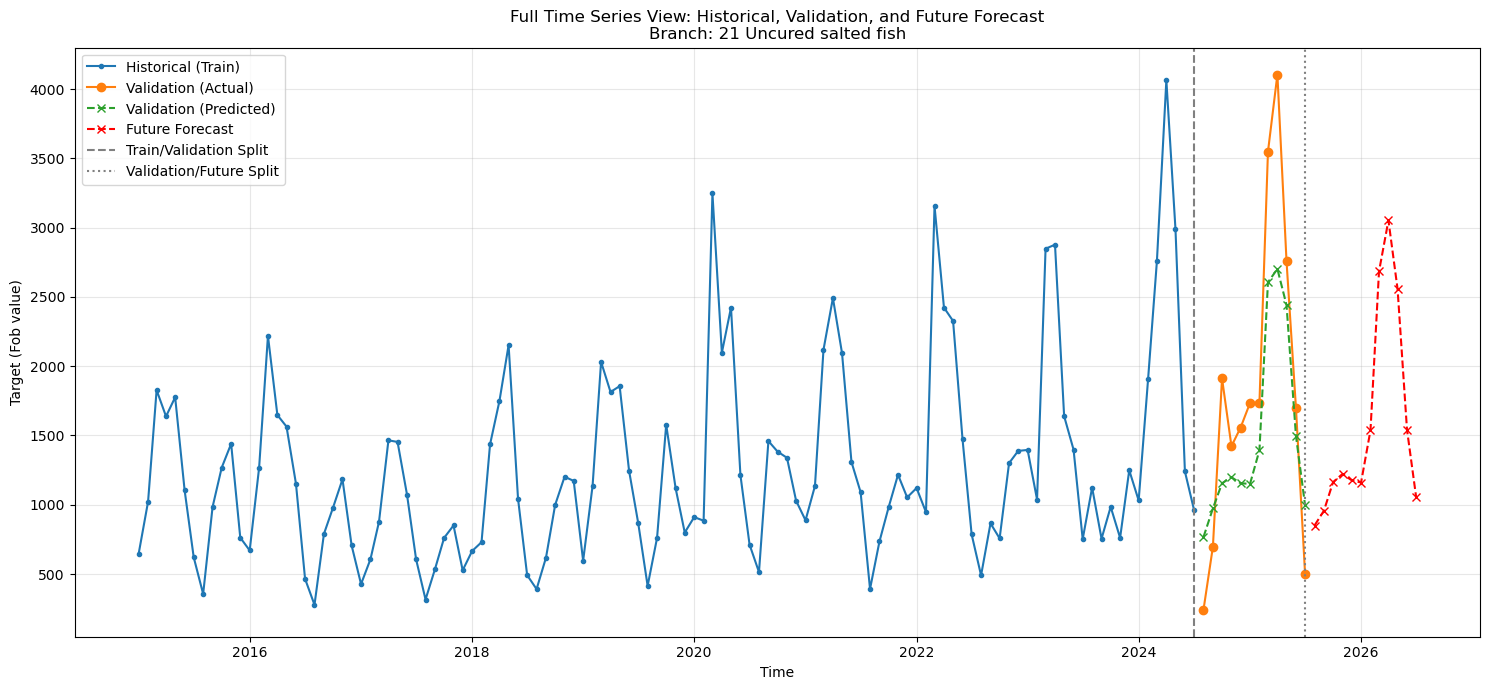


Plotting for: 89 Other manufacturing, n.e.s.


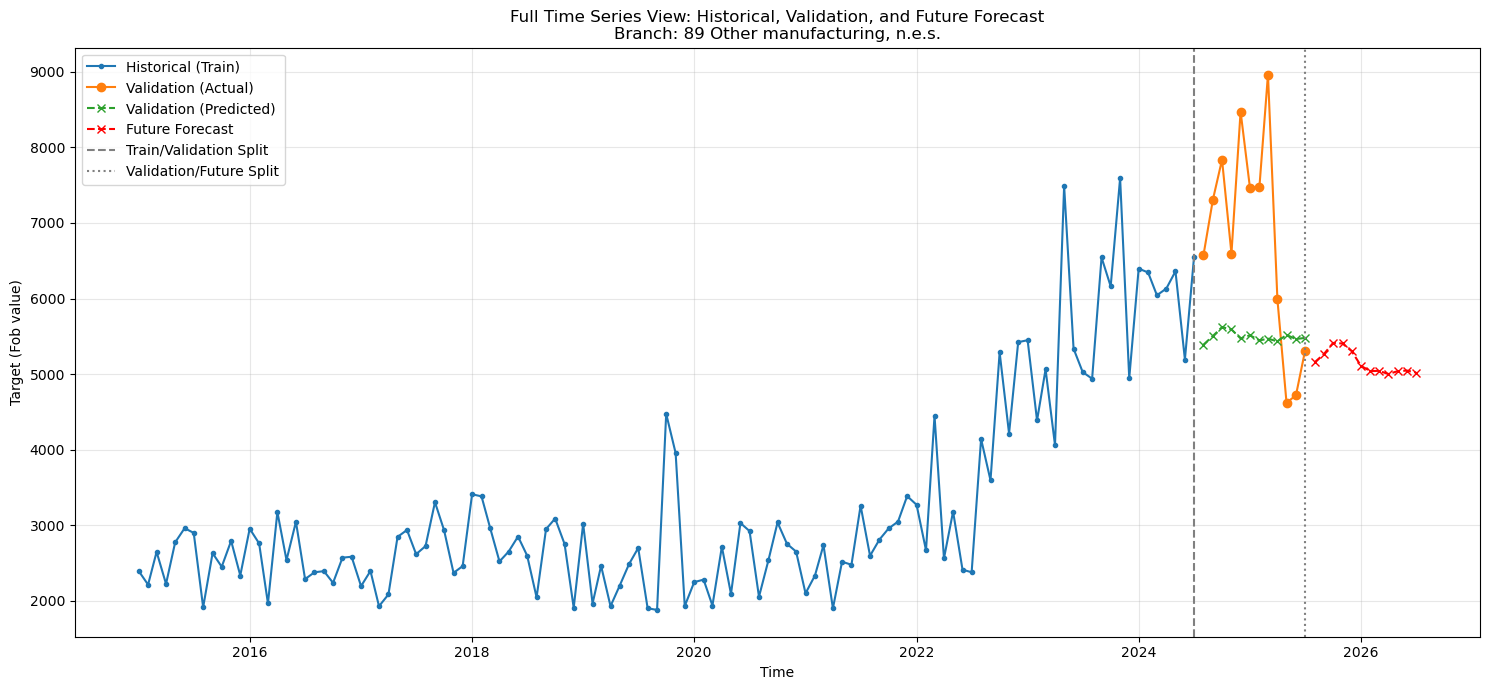


Plotting for: 16 Frozen fish fillets n.e.s.


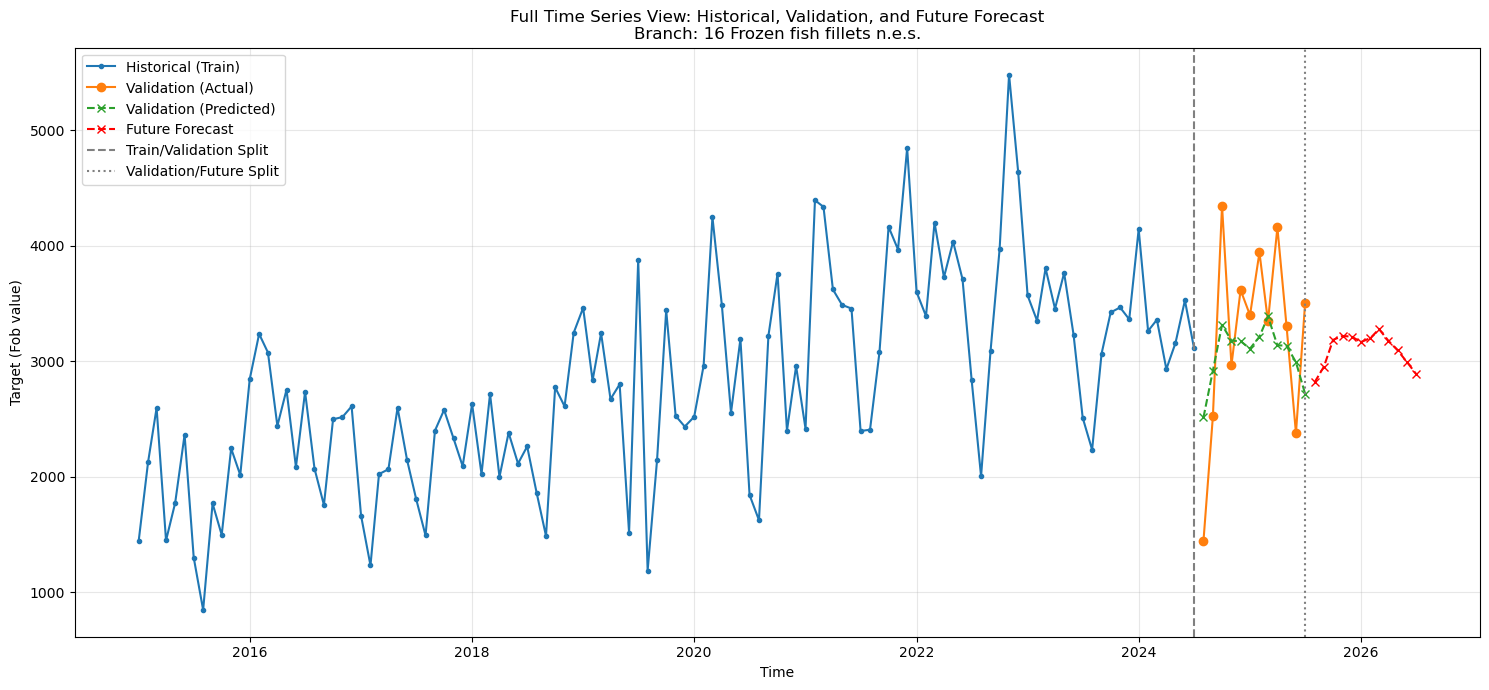


Plotting for: 41 Farmed fish


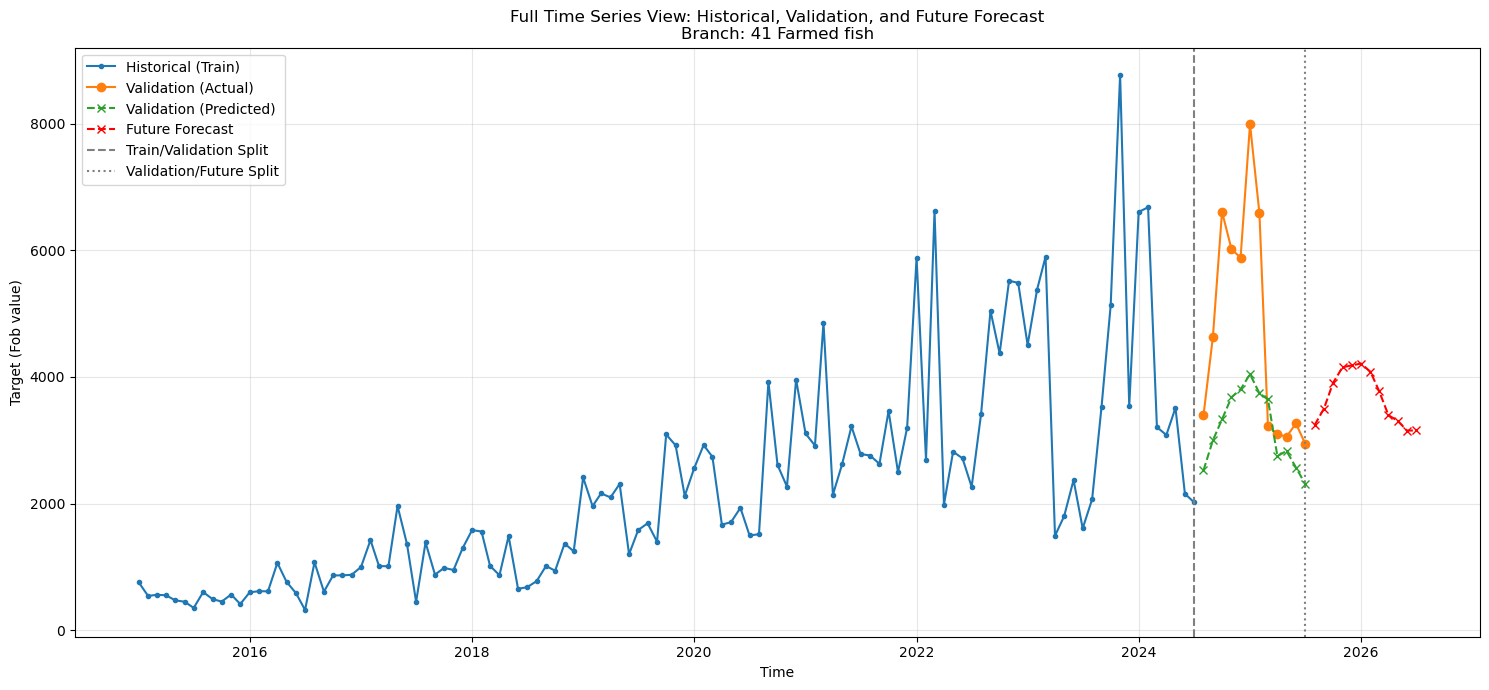


Plotting for: 29 Other dried, salted fish


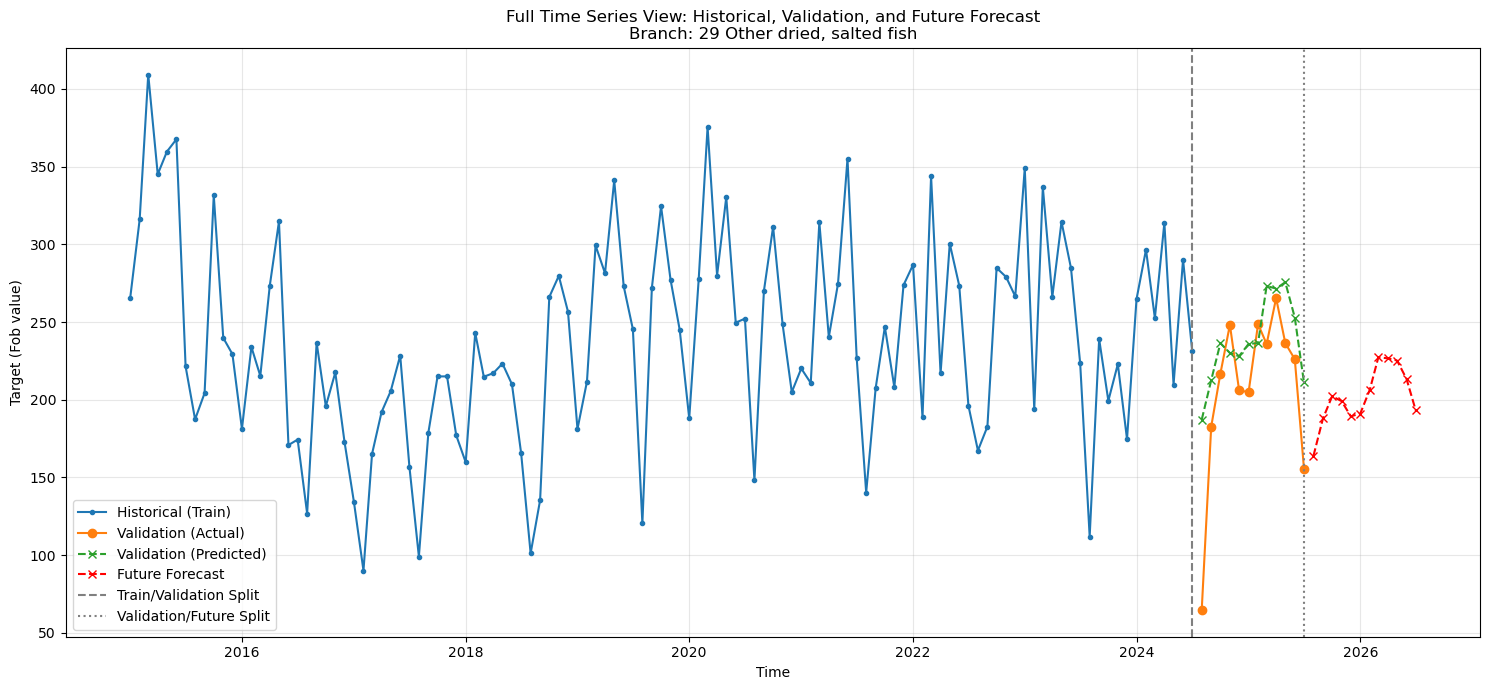


Plotting for: 12 Sea frozen fish fillets, n.e.s.


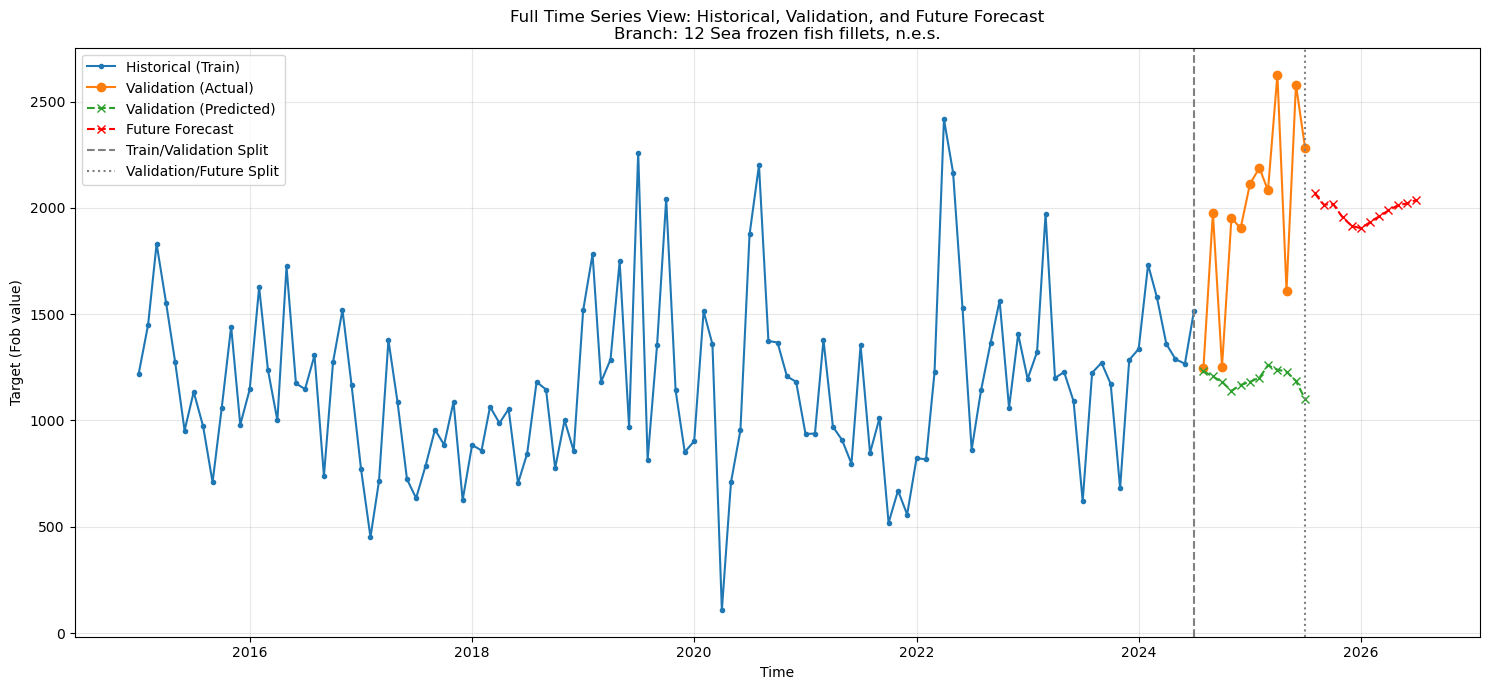


All plots generated.


In [29]:
# Get the names of the top 3 best-performing branches from your original 'by_branch' DataFrame
top_3_branches = by_branch["Branches"].head(10).tolist()

print(f"Generating plots for the top 3 branches: {top_3_branches}")

# Loop through each of the top 3 branches and create a plot
for target_branch_name in top_3_branches:
    
    print(f"\nPlotting for: {target_branch_name}")

    # --- 1. Get Series IDs for the current branch ---
    target_series_ids = series_meta[series_meta['Branches'] == target_branch_name]['series_id'].unique()
    
    # Check if we found any series for this branch
    if len(target_series_ids) == 0:
        print(f"  Skipping '{target_branch_name}', no series IDs found.")
        continue

    # --- 2. Aggregate Historical (Train) Data ---
    train_data_df = ts_train.reset_index()
    if "item_id" in train_data_df.columns:
        train_data_df = train_data_df.rename(columns={"item_id": "series_id"})
        
    branch_train_history = train_data_df[train_data_df['series_id'].isin(target_series_ids)]
    agg_branch_train = branch_train_history.groupby('timestamp')[['target']].sum().reset_index()

    # --- 3. Aggregate Validation (Test) Data ---
    # Use the 'aligned' DataFrame, which has the original validation predictions
    branch_validation_df = aligned[aligned['Branches'] == target_branch_name]
    agg_branch_validation = branch_validation_df.groupby('timestamp')[['y_true', 'y_pred']].sum().reset_index()

    # --- 4. Aggregate Future Forecast Data ---
    # This uses 'future_forecast' from the retrained model
    future_forecast_df = future_forecast.reset_index()
    if "item_id" in future_forecast_df.columns:
        future_forecast_df = future_forecast_df.rename(columns={"item_id": "series_id"})

    branch_forecast_df = future_forecast_df[future_forecast_df['series_id'].isin(target_series_ids)]
    agg_branch_forecast = branch_forecast_df.groupby('timestamp')[['mean']].sum().reset_index()

    # --- 5. Visualize the Full Time Series ---
    plt.figure(figsize=(15, 7))

    # Plot Historical (Train) Data
    plt.plot(
        agg_branch_train['timestamp'],
        agg_branch_train['target'],
        label='Historical (Train)',
        marker='.'
    )

    # Plot Validation (Actual) Data
    plt.plot(
        agg_branch_validation['timestamp'],
        agg_branch_validation['y_true'],
        label='Validation (Actual)',
        marker='o'
    )

    # Plot Validation (Predicted) Data
    plt.plot(
        agg_branch_validation['timestamp'],
        agg_branch_validation['y_pred'],
        label='Validation (Predicted)',
        marker='x',
        linestyle='--'
    )

    # Plot Future Forecast Data
    plt.plot(
        agg_branch_forecast['timestamp'],
        agg_branch_forecast['mean'],
        label='Future Forecast',
        marker='x',
        linestyle='--',
        color='red'
    )

    # Add vertical lines to separate the periods
    plt.axvline(agg_branch_train['timestamp'].max(), color='gray', linestyle='--', label='Train/Validation Split')
    plt.axvline(agg_branch_validation['timestamp'].max(), color='gray', linestyle=':', label='Validation/Future Split')

    # Add plot formatting
    plt.title(f"Full Time Series View: Historical, Validation, and Future Forecast\nBranch: {target_branch_name}")
    plt.xlabel("Time")
    plt.ylabel("Target (Fob value)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

print("\nAll plots generated.")